# Practical Exam — Set C
**Complete solution: ANN, OpenCV, CNN, GRU time-series forecasting, Transformers, comparison and GitHub submission**

This notebook follows the six steps in the exam brief. It downloads/loads public datasets where needed, trains models, evaluates them, saves models and OpenCV outputs, and creates summary/report files.


## 0. Setup and reproducibility

In [1]:
# If required, uncomment and run in a notebook cell:
# %pip install -U numpy pandas matplotlib seaborn scikit-learn tensorflow opencv-python scikit-image transformers torch

import os, sys, time, json, random, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version)
print("Platform:", platform.platform())
print("Output directory:", OUTPUT_DIR.resolve())

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Platform: Windows-11-10.0.26300-SP0
Output directory: D:\deep learning\practical exam\outputs


## Step 1 — ANN: Wine Recognition multi-class classification

### 1.1 Load and preprocess
Dataset: scikit-learn Wine dataset (178 rows, 13 numeric chemical measurements, 3 classes). We use an 80/20 stratified split and fit the scaler on training data only.

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras import layers

wine = load_wine(as_frame=True)
df_wine = wine.frame.copy()
display(df_wine.head())
print("Shape:", df_wine.shape)
print("\\nMissing values:\\n", df_wine.isna().sum())
display(df_wine.describe().T)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Shape: (178, 14)
\nMissing values:\n alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


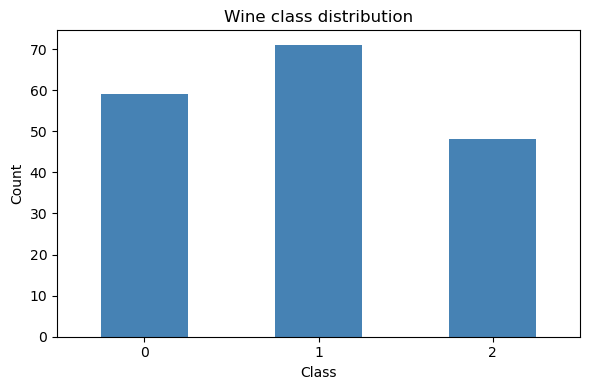

,min,max,range
proline,278.00,1680.0,1402.00
magnesium,70.00,162.0,92.00
alcalinity_of_ash,10.60,30.0,19.40
color_intensity,1.28,13.0,11.72
malic_acid,0.74,5.8,5.06


Features have different scales; StandardScaler helps the ANN optimize more reliably.


In [3]:
class_counts = df_wine["target"].value_counts().sort_index()
plt.figure(figsize=(6,4))
class_counts.plot(kind="bar", color="steelblue")
plt.title("Wine class distribution")
plt.xlabel("Class"); plt.ylabel("Count"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

feature_ranges = df_wine.drop(columns="target").agg(["min","max"]).T
feature_ranges["range"] = feature_ranges["max"] - feature_ranges["min"]
display(feature_ranges.sort_values("range", ascending=False).head(5))
print("Features have different scales; StandardScaler helps the ANN optimize more reliably.")

In [4]:
X_wine = df_wine.drop(columns="target").to_numpy(dtype=np.float32)
y_wine = df_wine["target"].to_numpy(dtype=np.int64)
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.20, random_state=SEED, stratify=y_wine
)
scaler_wine = StandardScaler()
X_train_w = scaler_wine.fit_transform(X_train_w).astype("float32")
X_test_w = scaler_wine.transform(X_test_w).astype("float32")

y_train_w_cat = keras.utils.to_categorical(y_train_w, num_classes=3)
y_test_w_cat = keras.utils.to_categorical(y_test_w, num_classes=3)
print("X_train:", X_train_w.shape, "X_test:", X_test_w.shape)
print("y_train one-hot:", y_train_w_cat.shape, "y_test one-hot:", y_test_w_cat.shape)

X_train: (142, 13) X_test: (36, 13)
y_train one-hot: (142, 3) y_test one-hot: (36, 3)


### 1.2 Build the ANN

In [5]:
ann_wine = keras.Sequential([
    layers.Input(shape=(13,), name="chemical_features"),
    layers.Dense(16, activation="relu", name="hidden_1"),
    layers.Dense(8, activation="relu", name="hidden_2"),
    layers.Dense(3, activation="softmax", name="class_probabilities")
], name="wine_ann")

ann_wine.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
ann_wine.summary()

Model: "wine_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 387 (1.51 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

**Parameter-count check:** first hidden layer has `(13 × 16) + 16 = 224` parameters (weights plus biases).  
**Reflection:** hidden layers learn nonlinear combinations of chemical measurements. Softmax turns the three output scores into probabilities summing to 1. Categorical cross-entropy is appropriate for one-hot encoded multi-class labels; sigmoid is normally used for independent binary/multi-label outputs.

### 1.3 Train and evaluate

In [6]:
start = time.time()
history_wine = ann_wine.fit(
    X_train_w, y_train_w_cat, epochs=60, batch_size=8,
    validation_split=0.2, verbose=0
)
wine_minutes = (time.time() - start) / 60

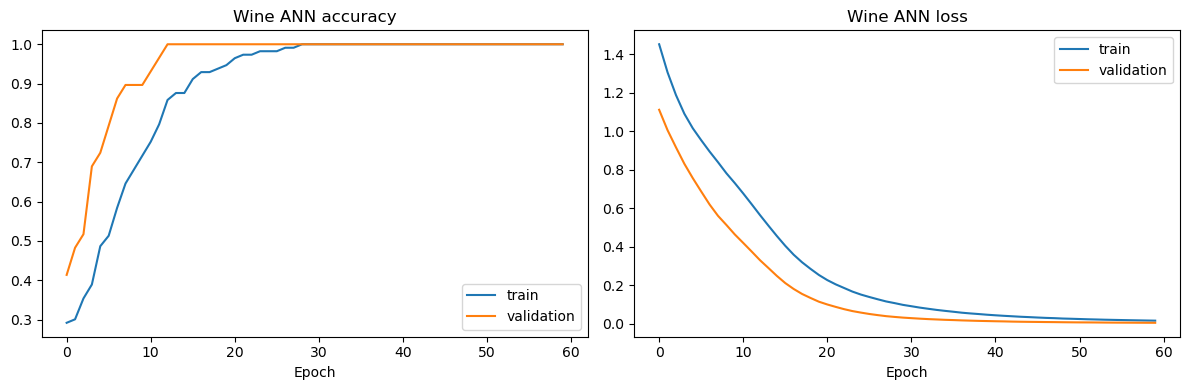

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(history_wine.history["accuracy"], label="train")
ax[0].plot(history_wine.history["val_accuracy"], label="validation")
ax[0].set_title("Wine ANN accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history_wine.history["loss"], label="train")
ax[1].plot(history_wine.history["val_loss"], label="validation")
ax[1].set_title("Wine ANN loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Test accuracy: 91.667%
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.87      0.93      0.90        14
     class_2       1.00      0.80      0.89        10

    accuracy                           0.92        36
   macro avg       0.93      0.91      0.92        36
weighted avg       0.92      0.92      0.92        36



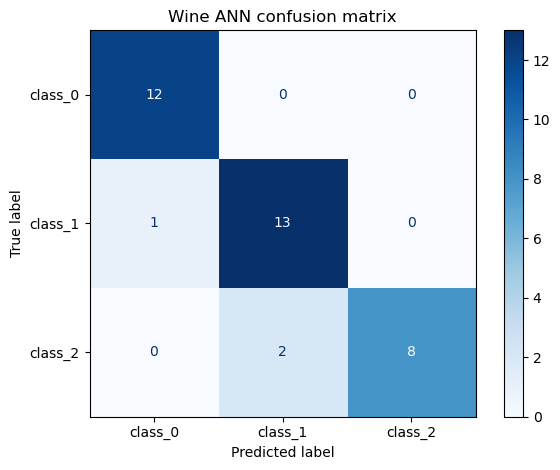

In [8]:
wine_prob = ann_wine.predict(X_test_w, verbose=0)
wine_pred = np.argmax(wine_prob, axis=1)
wine_accuracy = accuracy_score(y_test_w, wine_pred)
print(f"Test accuracy: {wine_accuracy:.3%}")
print(classification_report(y_test_w, wine_pred, target_names=wine.target_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_w, wine_pred, display_labels=wine.target_names, cmap="Blues")
plt.title("Wine ANN confusion matrix"); plt.tight_layout(); plt.show()

### 1.4 Save and reflect

In [9]:
ann_wine.save("ann_wine_model.h5")
print("Saved ann_wine_model.h5")

Saved ann_wine_model.h5


**Reflection:** the input layer accepts 13 scaled features; the two ReLU hidden layers learn nonlinear patterns; the three-unit softmax output gives a probability for each cultivar. The probabilities sum to approximately 1. Accuracy varies with the random split and training environment, so report the actual measured score rather than assuming a target score.

## Step 2 — OpenCV: colour, morphology, Sobel edges and Haar-cascade face detection

### 2.1 Load and display five images
This solution uses four scikit-image sample images and one additional sample when available. OpenCV uses BGR ordering, while Matplotlib expects RGB, so conversion is performed for display.

astronaut shape: (512, 512, 3) dtype: uint8 min: 0 max: 255 mean brightness: 114.6


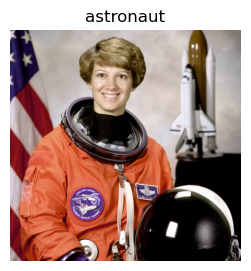

coffee shape: (400, 600, 3) dtype: uint8 min: 0 max: 255 mean brightness: 98.62


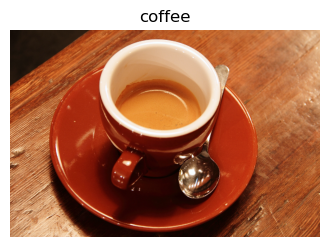

chelsea shape: (300, 451, 3) dtype: uint8 min: 0 max: 231 mean brightness: 115.31


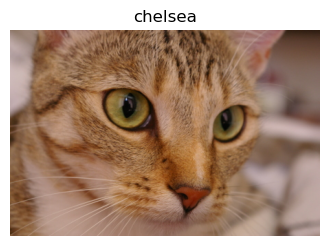

rocket shape: (427, 640, 3) dtype: uint8 min: 0 max: 255 mean brightness: 65.28


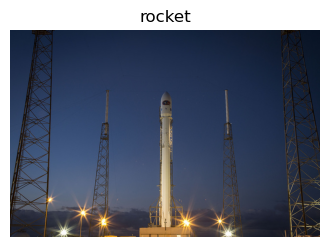

hubble shape: (872, 1000, 3) dtype: uint8 min: 0 max: 255 mean brightness: 19.15


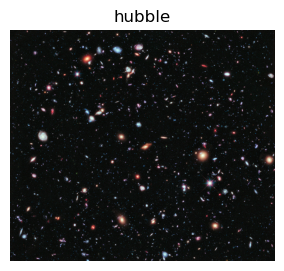

In [10]:
import cv2
from skimage import data

def to_uint8_rgb(arr):
    arr = np.asarray(arr)
    if arr.dtype != np.uint8:
        if arr.max() <= 1.0:
            arr = (arr * 255).clip(0,255).astype(np.uint8)
        else:
            arr = arr.clip(0,255).astype(np.uint8)
    if arr.ndim == 2:
        arr = cv2.cvtColor(arr, cv2.COLOR_GRAY2RGB)
    if arr.shape[-1] == 4:
        arr = arr[..., :3]
    return arr

sample_images = {
    "astronaut": to_uint8_rgb(data.astronaut()),
    "coffee": to_uint8_rgb(data.coffee()),
    "chelsea": to_uint8_rgb(data.chelsea()),
    "rocket": to_uint8_rgb(data.rocket()),
    "hubble": to_uint8_rgb(data.hubble_deep_field())
}
# Resize a little for faster processing while preserving aspect ratio at load time.
for name, img in sample_images.items():
    print(name, "shape:", img.shape, "dtype:", img.dtype,
          "min:", int(img.min()), "max:", int(img.max()), "mean brightness:", round(float(img.mean()),2))
    plt.figure(figsize=(4,3)); plt.imshow(img); plt.title(name); plt.axis("off"); plt.show()

### 2.2 Processing operations — HSV mask, morphology, Sobel edges

In [11]:
def process_opencv_image(rgb, lower_hsv=(0, 70, 50), upper_hsv=(10, 255, 255)):
    rgb = cv2.resize(rgb, (256, 256))
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    lower = np.array(lower_hsv, dtype=np.uint8)
    upper = np.array(upper_hsv, dtype=np.uint8)
    mask = cv2.inRange(hsv, lower, upper)
    kernel = np.ones((5,5), np.uint8)
    cleaned = cv2.dilate(cv2.erode(mask, kernel, iterations=1), kernel, iterations=1)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    edges = cv2.convertScaleAbs(cv2.magnitude(sx, sy))
    return rgb, hsv, mask, cleaned, edges

processed_images = {}
for name, img in sample_images.items():
    processed_images[name] = process_opencv_image(img)
print("Processed", len(processed_images), "images.")

Processed 5 images.


### 2.3 Haar cascade face detection

In [ ]:
cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(cascade_path)
cascade_path = os.path.join(
    os.getcwd(),
    "haarcascade_frontalface_default.xml"
)

face_cascade = cv2.CascadeClassifier(cascade_path)

face_counts = {}
face_results = {}
for name, (rgb, hsv, mask, cleaned, edges) in processed_images.items():
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30,30))
    annotated = rgb.copy()
    for (x,y,w,h) in faces:
        cv2.rectangle(annotated, (x,y), (x+w,y+h), (0,0,255), 2)
        cv2.putText(annotated, "Face", (x, max(15,y-5)), cv2.FONT_HERSHEY_SIMPLEX, .5, (0,0,255), 1)
    face_counts[name] = len(faces)
    face_results[name] = annotated
    cv2.imwrite(str(OUTPUT_DIR / f"{name}_face_detection.jpg"), cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR))
    print(f"{name}: {len(faces)} face(s)")
display(pd.DataFrame({"Image": list(face_counts.keys()), "Faces detected": list(face_counts.values())}))

astronaut: 1 face(s)
coffee: 0 face(s)
chelsea: 0 face(s)
rocket: 0 face(s)
hubble: 0 face(s)


,Image,Faces detected
0,astronaut,1
1,coffee,0
2,chelsea,0
3,rocket,0
4,hubble,0


In [26]:
# Compare minNeighbors settings on the astronaut sample (usually contains a face).
rgb = processed_images["astronaut"][0]
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
neighbor_results = {}
for neighbors in (2, 5, 8):
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=neighbors, minSize=(30,30))
    neighbor_results[neighbors] = len(faces)
print("Face counts by minNeighbors:", neighbor_results)

Face counts by minNeighbors: {2: 2, 5: 1, 8: 1}


### 2.4 Five-by-five summary grid

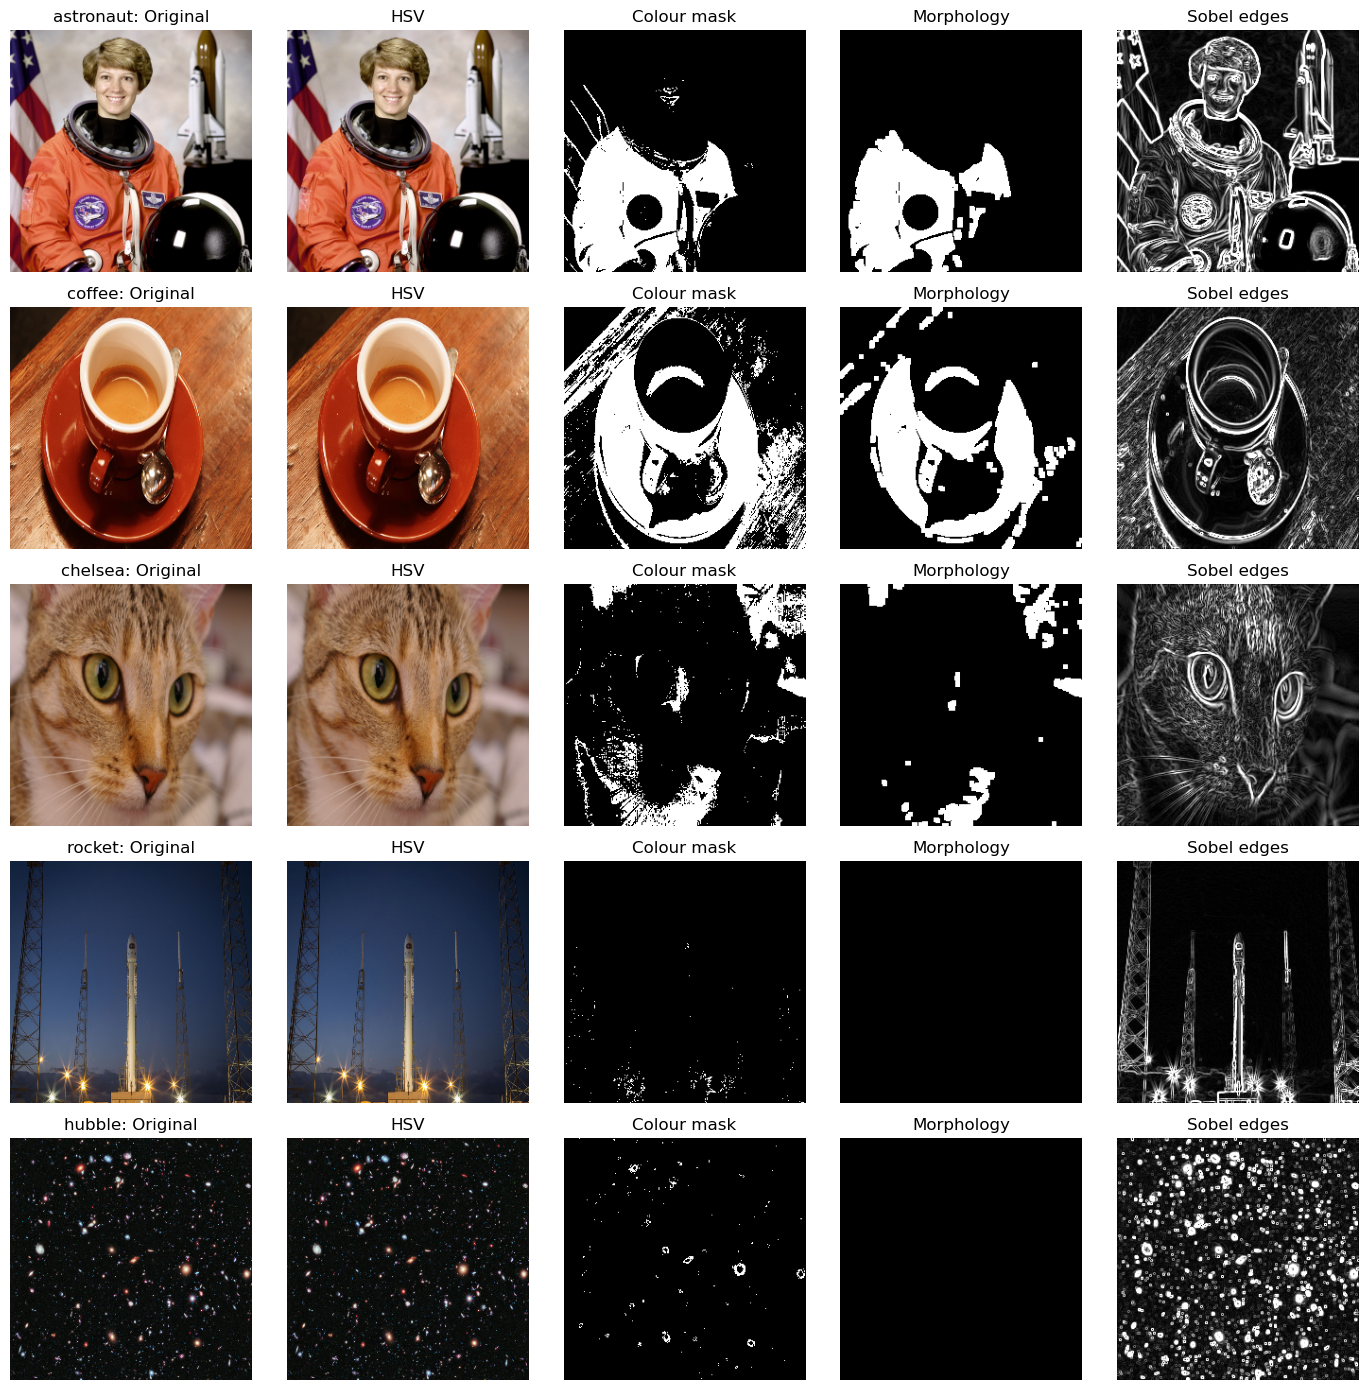

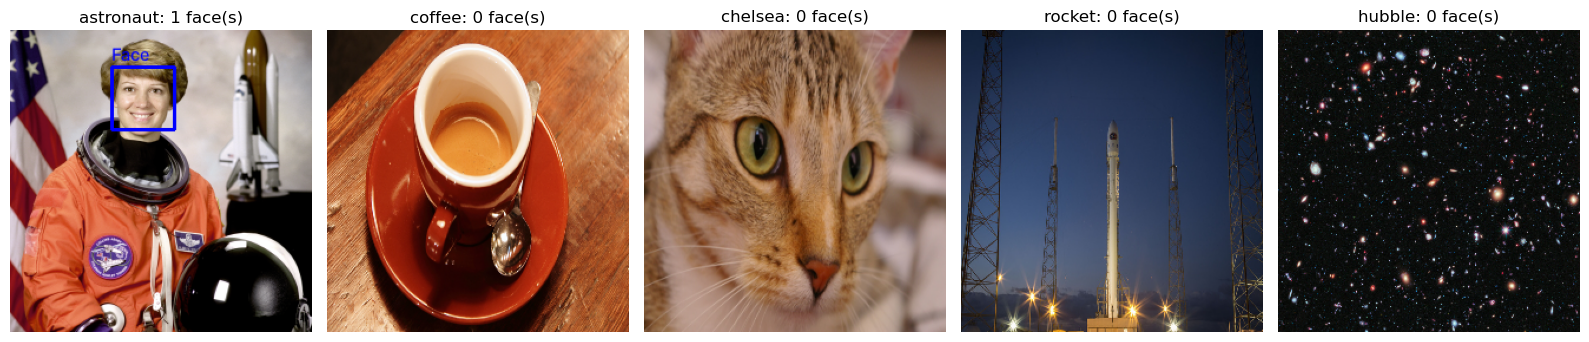

In [27]:
fig, axes = plt.subplots(5, 5, figsize=(14,14))
for row, (name, (rgb, hsv, mask, cleaned, edges)) in enumerate(processed_images.items()):
    axes[row,0].imshow(rgb); axes[row,0].set_title(f"{name}: Original")
    axes[row,1].imshow(cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)); axes[row,1].set_title("HSV")
    axes[row,2].imshow(mask, cmap="gray"); axes[row,2].set_title("Colour mask")
    axes[row,3].imshow(cleaned, cmap="gray"); axes[row,3].set_title("Morphology")
    axes[row,4].imshow(edges, cmap="gray"); axes[row,4].set_title("Sobel edges")
    for ax in axes[row]: ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1,5, figsize=(16,4))
for ax, (name, annotated) in zip(axes, face_results.items()):
    ax.imshow(annotated); ax.set_title(f"{name}: {face_counts[name]} face(s)"); ax.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** HSV separates hue from brightness more naturally than RGB/BGR, making colour thresholding easier under some lighting changes. Erosion removes small foreground noise and shrinks regions; dilation expands regions and can reconnect gaps. Haar cascades use hand-designed cascade features/classifiers; CNNs learn features from training data and are usually more flexible, but require training data and more computation. Face detections can be false positives or missed faces depending on pose, size, lighting, and `minNeighbors`.

## Step 3 — CNN vs plain ANN on MNIST

### 3.1 Load and prepare data (20,000 train / 4,000 test samples)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 8s 1us/step
CNN train/test: (20000, 28, 28, 1) (4000, 28, 28, 1)
Labels: (20000, 10) (4000, 10)


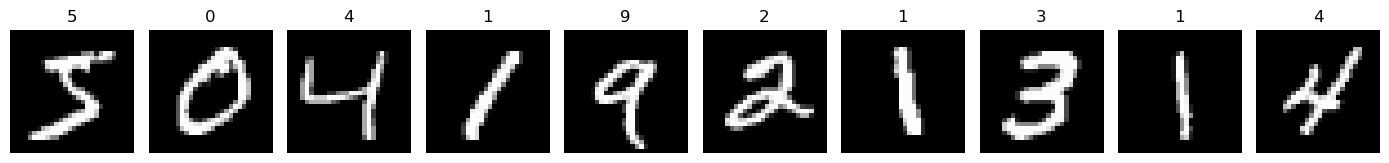

In [28]:
from tensorflow.keras.datasets import mnist
from sklearn.metrics import ConfusionMatrixDisplay

(X_train_full, y_train_full), (X_test_full, y_test_full) = mnist.load_data()
X_train_c = X_train_full[:20000].astype("float32") / 255.0
y_train_c = y_train_full[:20000]
X_test_c = X_test_full[:4000].astype("float32") / 255.0
y_test_c = y_test_full[:4000]
X_train_cnn = X_train_c[..., np.newaxis]
X_test_cnn = X_test_c[..., np.newaxis]
y_train_c_cat = keras.utils.to_categorical(y_train_c, 10)
y_test_c_cat = keras.utils.to_categorical(y_test_c, 10)
print("CNN train/test:", X_train_cnn.shape, X_test_cnn.shape)
print("Labels:", y_train_c_cat.shape, y_test_c_cat.shape)

fig, axes = plt.subplots(1,10, figsize=(14,2))
for i, ax in enumerate(axes):
    ax.imshow(X_train_c[i], cmap="gray"); ax.set_title(str(y_train_c[i])); ax.axis("off")
plt.tight_layout(); plt.show()

### 3.2 Build CNN and ANN baseline

In [29]:
cnn_mnist = keras.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(16, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(32, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="mnist_cnn")
cnn_mnist.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
cnn_mnist.summary()

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
ann_mnist = keras.Sequential([
    layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="mnist_ann_baseline")
ann_mnist.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
ann_mnist.summary()
print("CNN parameters:", cnn_mnist.count_params())
print("ANN parameters:", ann_mnist.count_params())

Model: "mnist_ann_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

CNN parameters: 56714
ANN parameters: 109386


### 3.3 Train and evaluate both models

In [31]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
start = time.time()
history_cnn = cnn_mnist.fit(
    X_train_cnn, y_train_c_cat, epochs=8, batch_size=64,
    validation_split=0.1, callbacks=[early_stop], verbose=1
)
cnn_minutes = (time.time()-start)/60

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8722 - loss: 0.4364 - val_accuracy: 0.9640 - val_loss: 0.1320
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9629 - loss: 0.1229 - val_accuracy: 0.9775 - val_loss: 0.0885
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9756 - loss: 0.0839 - val_accuracy: 0.9760 - val_loss: 0.0775
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9807 - loss: 0.0631 - val_accuracy: 0.9805 - val_loss: 0.0576
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9838 - loss: 0.0510 - val_accuracy: 0.9750 - val_loss: 0.0737
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9871 - loss: 0.0433 - val_accuracy: 0.9825 - val_loss: 0.0559
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9891 - loss: 0.0337 - val_accuracy: 0.9815 - val_loss: 0.0601
Epoch 8/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9909 - loss: 0.0290 - val_accuracy: 0.9810 - v

In [32]:
start = time.time()
history_ann = ann_mnist.fit(
    X_train_c, y_train_c_cat, epochs=8, batch_size=64,
    validation_split=0.1, callbacks=[early_stop], verbose=1
)
ann_minutes = (time.time()-start)/60

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8666 - loss: 0.4856 - val_accuracy: 0.9390 - val_loss: 0.2170
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9409 - loss: 0.2049 - val_accuracy: 0.9505 - val_loss: 0.1629
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9592 - loss: 0.1396 - val_accuracy: 0.9540 - val_loss: 0.1561
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9702 - loss: 0.1006 - val_accuracy: 0.9640 - val_loss: 0.1264
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9769 - loss: 0.0773 - val_accuracy: 0.9625 - val_loss: 0.1271
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9812 - loss: 0.0627 - val_accuracy: 0.9640 - val_loss: 0.1259
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9883 - loss: 0.0457 - val_accuracy: 0.9615 - val_loss: 0.1268
Epoch 8/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9900 - loss: 0.0358 - val_accuracy: 0.9660 - v

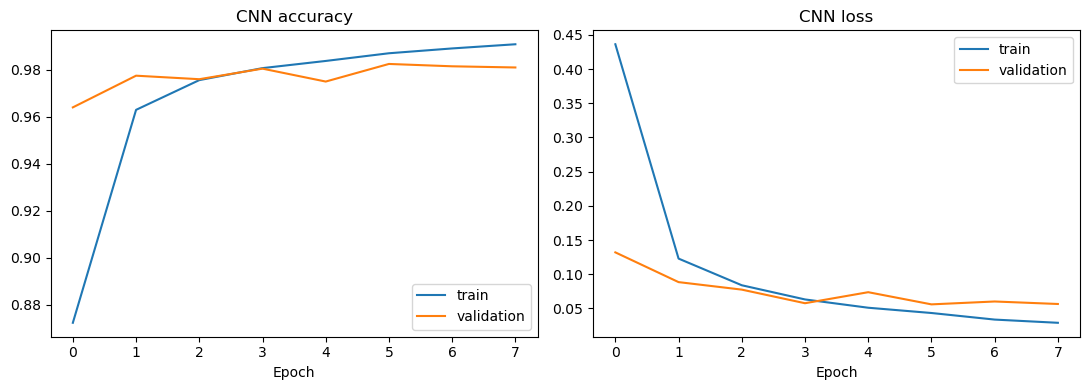

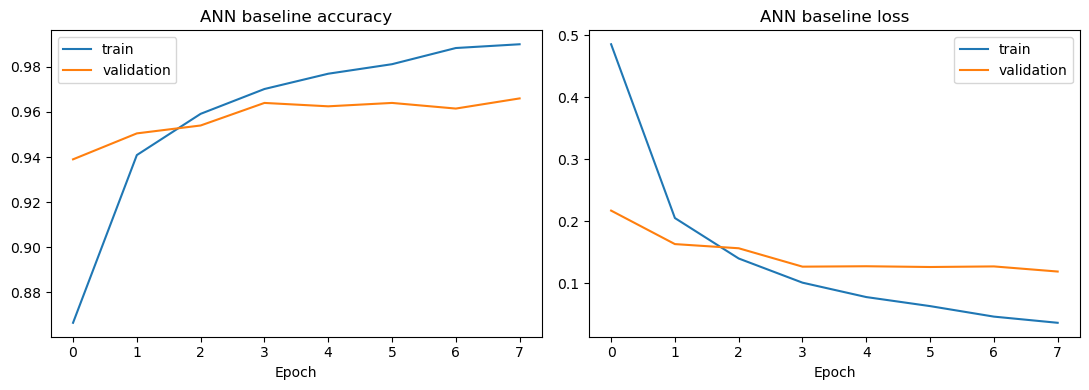

In [33]:
def plot_history(history, title):
    fig, ax = plt.subplots(1,2,figsize=(11,4))
    ax[0].plot(history.history["accuracy"], label="train")
    ax[0].plot(history.history["val_accuracy"], label="validation")
    ax[0].set_title(title+" accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history.history["loss"], label="train")
    ax[1].plot(history.history["val_loss"], label="validation")
    ax[1].set_title(title+" loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()
plot_history(history_cnn, "CNN")
plot_history(history_ann, "ANN baseline")

CNN test accuracy: 0.9765
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       370
           1       0.98      0.99      0.99       450
           2       0.98      0.98      0.98       418
           3       0.98      0.96      0.97       408
           4       0.98      0.99      0.98       418
           5       0.96      0.98      0.97       372
           6       0.99      0.97      0.98       378
           7       0.96      0.98      0.97       411
           8       0.98      0.97      0.98       384
           9       0.98      0.96      0.97       391

    accuracy                           0.98      4000
   macro avg       0.98      0.98      0.98      4000
weighted avg       0.98      0.98      0.98      4000



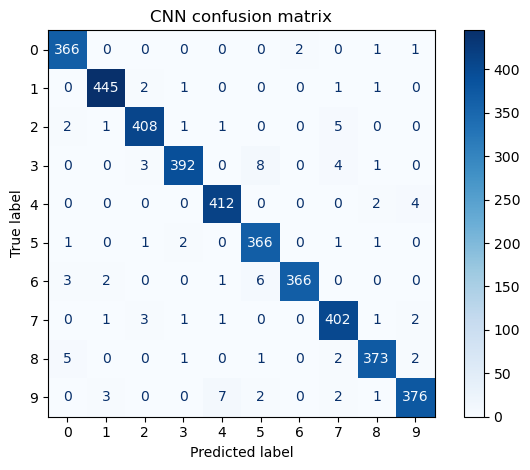

,Model,Parameters,Test accuracy,Minutes
0,CNN,56714,0.97650,0.304144
1,ANN baseline,109386,0.95625,0.169677


In [34]:
cnn_prob = cnn_mnist.predict(X_test_cnn, verbose=0)
cnn_pred = np.argmax(cnn_prob, axis=1)
ann_prob = ann_mnist.predict(X_test_c, verbose=0)
ann_pred = np.argmax(ann_prob, axis=1)
cnn_accuracy = accuracy_score(y_test_c, cnn_pred)
ann_accuracy = accuracy_score(y_test_c, ann_pred)
print("CNN test accuracy:", round(cnn_accuracy,4))
print(classification_report(y_test_c, cnn_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test_c, cnn_pred, cmap="Blues")
plt.title("CNN confusion matrix"); plt.tight_layout(); plt.show()

comparison_mnist = pd.DataFrame([
    {"Model":"CNN", "Parameters":cnn_mnist.count_params(), "Test accuracy":cnn_accuracy, "Minutes":cnn_minutes},
    {"Model":"ANN baseline", "Parameters":ann_mnist.count_params(), "Test accuracy":ann_accuracy, "Minutes":ann_minutes}
])
display(comparison_mnist)

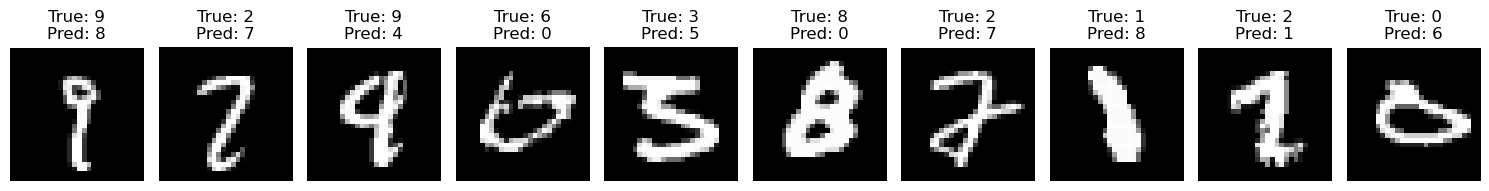

In [35]:
wrong = np.flatnonzero(cnn_pred != y_test_c)[:10]
fig, axes = plt.subplots(1, max(1,len(wrong)), figsize=(15,2.5))
if len(wrong) == 1: axes = [axes]
for ax, idx in zip(axes, wrong):
    ax.imshow(X_test_c[idx], cmap="gray")
    ax.set_title(f"True: {y_test_c[idx]}\nPred: {cnn_pred[idx]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

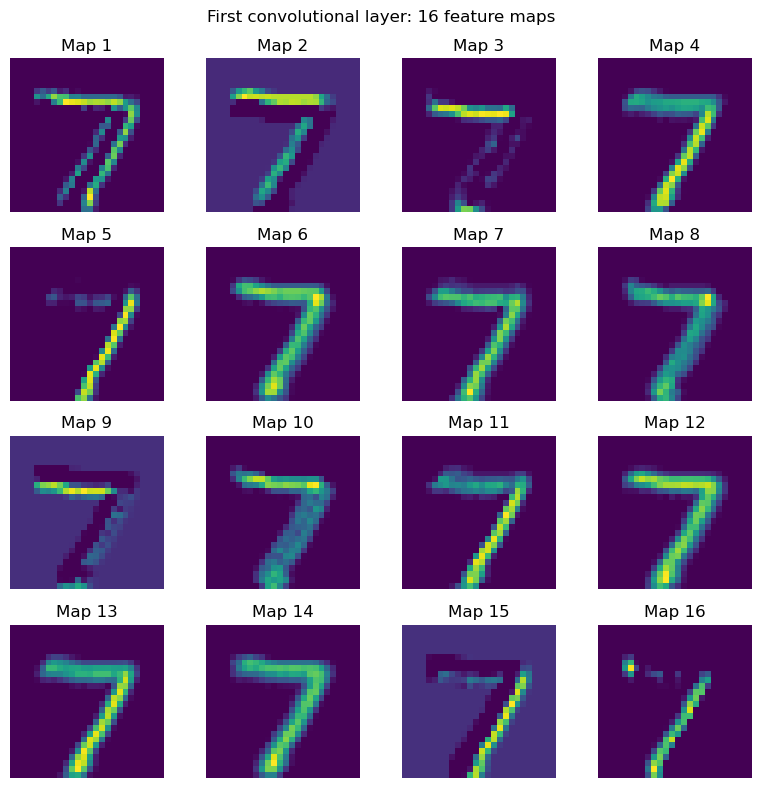

In [36]:
# Feature maps from the first convolutional layer for one test digit.
feature_model = keras.Model(inputs=cnn_mnist.inputs, outputs=cnn_mnist.layers[0].output)
feature_maps = feature_model.predict(X_test_cnn[:1], verbose=0)[0]
fig, axes = plt.subplots(4,4,figsize=(8,8))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[:,:,i], cmap="viridis"); ax.set_title(f"Map {i+1}"); ax.axis("off")
plt.suptitle("First convolutional layer: 16 feature maps")
plt.tight_layout(); plt.show()

### 3.4 Save and reflect

In [37]:
cnn_mnist.save("cnn_mnist_model.h5")
ann_mnist.save("ann_mnist_baseline.h5")
print("Saved cnn_mnist_model.h5 and ann_mnist_baseline.h5")

Saved cnn_mnist_model.h5 and ann_mnist_baseline.h5


**Reflection:** convolutional layers learn local visual patterns such as edges and strokes; max pooling reduces spatial dimensions and computation while retaining strong activations. The CNN often performs better on shifted or distorted digits because it preserves spatial structure. Parameter counts depend on the exact architecture; use the printed counts rather than assuming the CNN always has fewer parameters than every ANN.

## Step 4 — GRU for daily minimum temperatures

### 4.1 Load data, inspect, plot, split chronologically, and create sequences

In [38]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

temp_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
try:
    temp_df = pd.read_csv(temp_url, parse_dates=["Date"])
except Exception as e:
    print("Could not download temperature CSV. Ensure internet access is available.", repr(e))
    temp_df = pd.DataFrame(columns=["Date","Temp"])
display(temp_df.head())
if len(temp_df):
    print(temp_df.dtypes)
    display(temp_df.describe(include="all"))
    temp_df["Temp"] = pd.to_numeric(temp_df["Temp"], errors="coerce")
    print("Missing temperatures before cleanup:", temp_df["Temp"].isna().sum())
    temp_df["Temp"] = temp_df["Temp"].interpolate(limit_direction="both")
    print("Missing temperatures after interpolation:", temp_df["Temp"].isna().sum())

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


Date    datetime64[ns]
Temp           float64
dtype: object


,Date,Temp
count,3650,3650.000000
mean,1985-12-31 07:12:00,11.177753
min,1981-01-01 00:00:00,0.000000
25%,1983-07-02 06:00:00,8.300000
50%,1985-12-31 12:00:00,11.000000
75%,1988-06-30 18:00:00,14.000000
max,1990-12-31 00:00:00,26.300000
std,NaN,4.071837


Missing temperatures before cleanup: 0
Missing temperatures after interpolation: 0


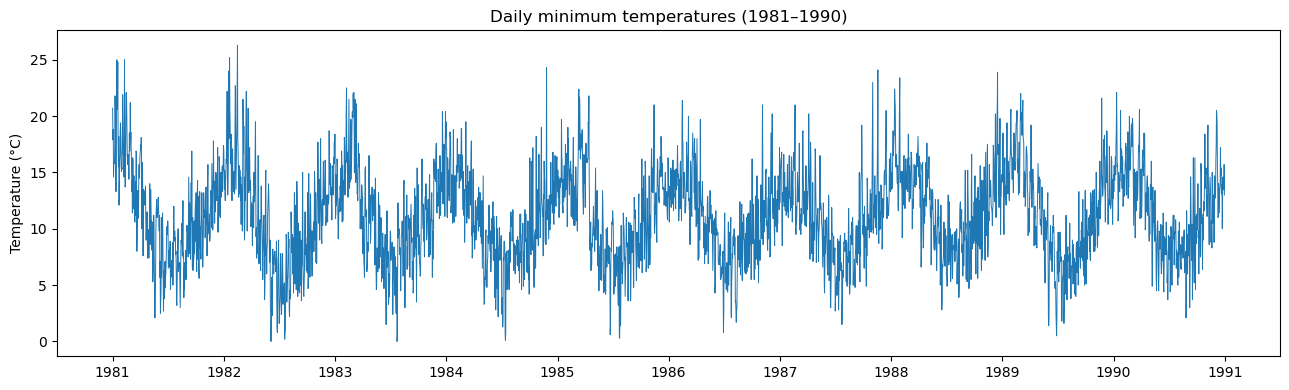

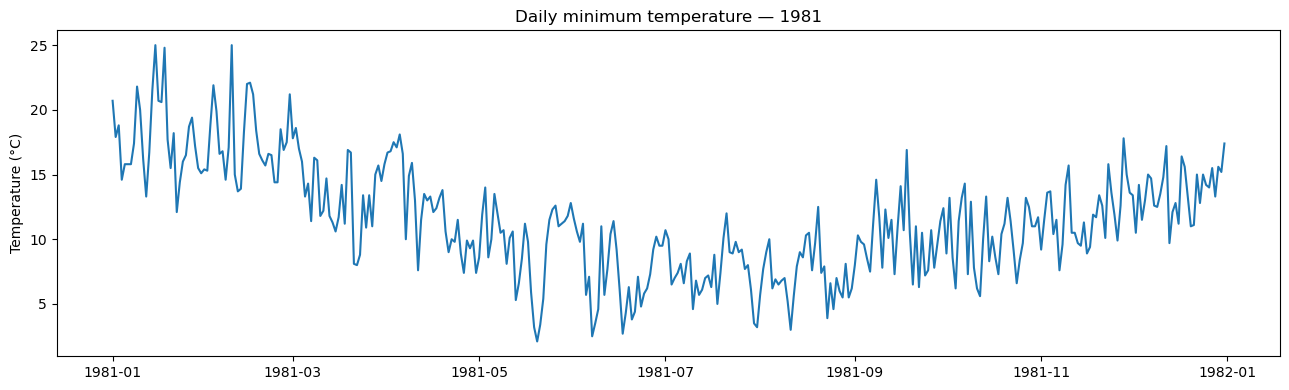

In [39]:
if len(temp_df):
    plt.figure(figsize=(13,4))
    plt.plot(temp_df["Date"], temp_df["Temp"], linewidth=.7)
    plt.title("Daily minimum temperatures (1981–1990)"); plt.ylabel("Temperature (°C)")
    plt.tight_layout(); plt.show()
    year_df = temp_df[temp_df["Date"].dt.year == 1981]
    plt.figure(figsize=(13,4)); plt.plot(year_df["Date"], year_df["Temp"])
    plt.title("Daily minimum temperature — 1981"); plt.ylabel("Temperature (°C)")
    plt.tight_layout(); plt.show()

In [40]:
if len(temp_df):
    temperatures = temp_df["Temp"].to_numpy(dtype="float32").reshape(-1,1)
    split_idx = int(len(temperatures)*0.8)
    train_raw, test_raw = temperatures[:split_idx], temperatures[split_idx:]
    temp_scaler = MinMaxScaler()
    train_scaled = temp_scaler.fit_transform(train_raw)
    # Include the preceding 30 observations so the first test target has a full history.
    combined_scaled = np.vstack([train_scaled, temp_scaler.transform(test_raw)])
    LOOK_BACK = 30
    def make_sequences(series, start_target, end_target, look_back=30):
        X, y = [], []
        for target_idx in range(start_target, end_target):
            X.append(series[target_idx-look_back:target_idx])
            y.append(series[target_idx])
        return np.asarray(X, dtype="float32"), np.asarray(y, dtype="float32")
    X_train_r, y_train_r = make_sequences(train_scaled, LOOK_BACK, len(train_scaled), LOOK_BACK)
    X_test_r, y_test_r = make_sequences(combined_scaled, split_idx, len(combined_scaled), LOOK_BACK)
    print("X_train:", X_train_r.shape, "y_train:", y_train_r.shape)
    print("X_test:", X_test_r.shape, "y_test:", y_test_r.shape)

X_train: (2890, 30, 1) y_train: (2890, 1)
X_test: (730, 30, 1) y_test: (730, 1)


### 4.2 Build GRU and naive baseline

In [41]:
if len(temp_df):
    gru_temp = keras.Sequential([
        layers.Input(shape=(30,1)),
        layers.GRU(32, activation="tanh"),
        layers.Dense(1)
    ], name="temperature_gru")
    gru_temp.compile(optimizer="adam", loss="mse")
    gru_temp.summary()

Model: "temperature_gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

### 4.3 Train and evaluate

In [42]:
if len(temp_df):
    start = time.time()
    history_gru = gru_temp.fit(
        X_train_r, y_train_r, epochs=15, batch_size=32,
        validation_split=0.1, verbose=1
    )
    gru_minutes = (time.time()-start)/60

Epoch 1/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0283 - val_loss: 0.0108
Epoch 2/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0111 - val_loss: 0.0100
Epoch 3/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0101 - val_loss: 0.0096
Epoch 4/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0097 - val_loss: 0.0096
Epoch 5/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0095 - val_loss: 0.0095
Epoch 6/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0093 - val_loss: 0.0092
Epoch 7/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0092 - val_loss: 0.0091
Epoch 8/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0089 - val_loss: 0.0091
Epoch 9/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0089 - val_loss: 0.0092
Epoch 10/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0090 - val_loss: 0.0092
Epoch 11/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0089 - val_loss: 0.0095
Epoch 12/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0089 

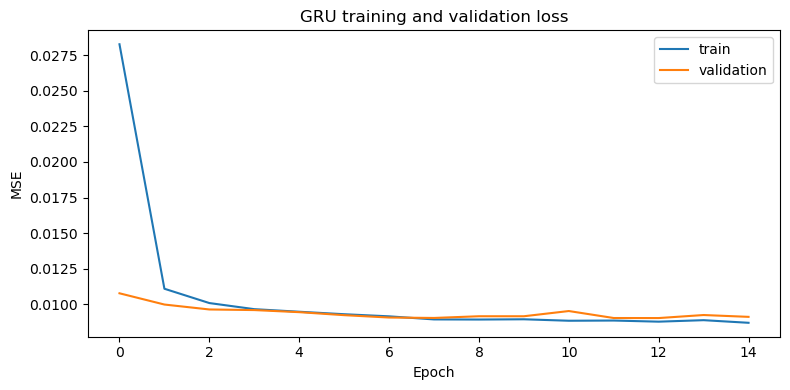

,Model,RMSE (°C),MAE (°C)
0,GRU,2.217855,1.743902
1,Naive persistence,2.480905,1.952740


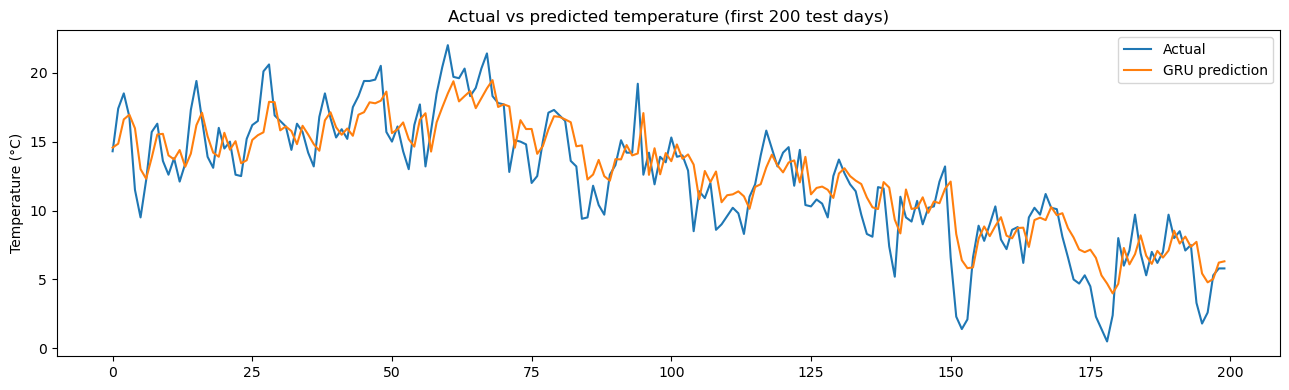

In [43]:
if len(temp_df):
    plt.figure(figsize=(8,4))
    plt.plot(history_gru.history["loss"], label="train")
    plt.plot(history_gru.history["val_loss"], label="validation")
    plt.title("GRU training and validation loss"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend()
    plt.tight_layout(); plt.show()

    gru_scaled_pred = gru_temp.predict(X_test_r, verbose=0)
    gru_pred = temp_scaler.inverse_transform(gru_scaled_pred).ravel()
    actual_temp = temp_scaler.inverse_transform(y_test_r).ravel()
    # Naive persistence baseline: tomorrow equals today's observed temperature.
    naive_scaled_pred = X_test_r[:, -1, 0].reshape(-1,1)
    naive_pred = temp_scaler.inverse_transform(naive_scaled_pred).ravel()
    gru_rmse = float(np.sqrt(mean_squared_error(actual_temp, gru_pred)))
    gru_mae = float(mean_absolute_error(actual_temp, gru_pred))
    naive_rmse = float(np.sqrt(mean_squared_error(actual_temp, naive_pred)))
    naive_mae = float(mean_absolute_error(actual_temp, naive_pred))
    display(pd.DataFrame([
        {"Model":"GRU", "RMSE (°C)":gru_rmse, "MAE (°C)":gru_mae},
        {"Model":"Naive persistence", "RMSE (°C)":naive_rmse, "MAE (°C)":naive_mae}
    ]))
    nplot = min(200, len(actual_temp))
    plt.figure(figsize=(13,4))
    plt.plot(actual_temp[:nplot], label="Actual")
    plt.plot(gru_pred[:nplot], label="GRU prediction")
    plt.title("Actual vs predicted temperature (first 200 test days)")
    plt.ylabel("Temperature (°C)"); plt.legend(); plt.tight_layout(); plt.show()

### 4.4 Save and reflect

In [44]:
if len(temp_df):
    gru_temp.save("rnn_temperature_model.h5")
    print("Saved rnn_temperature_model.h5")

Saved rnn_temperature_model.h5


**Reflection:** a GRU has update/reset gates that help it retain useful information across sequences and mitigate vanishing-gradient issues compared with a simple RNN. The scaler is fitted only on the training period to avoid leaking test-period information. RMSE penalizes large errors more strongly; MAE is the average absolute error. Lower values are better. Weather is noisy, so compare the GRU against the naive baseline instead of judging by a fixed target alone.

## Step 5 — Transformers: fill-mask, question answering, and text generation

**Dependencies:** `transformers` and `torch`. The first model load downloads pretrained weights and may require several hundred MB of disk space and internet access. This section uses pretrained models only; it does not fine-tune them.

In [45]:
try:
    from transformers import pipeline, set_seed
    import torch
    TRANSFORMERS_AVAILABLE = True
    set_seed(SEED)
    print("Torch:", torch.__version__)
except Exception as e:
    TRANSFORMERS_AVAILABLE = False
    print("Transformers setup unavailable:", repr(e))

Transformers setup unavailable: ModuleNotFoundError("No module named 'transformers'")


### 5.1 Fill-mask

In [46]:
india_paragraphs = [
    "The Indian Space Research Organisation is headquartered in [MASK].",
    "The Taj Mahal is located in the city of [MASK].",
    "Indian Railways is one of the world's largest railway [MASK].",
    "The Unified Payments Interface is commonly abbreviated as [MASK].",
    "Mumbai is a major city in the Indian state of [MASK]."
]
fill_results = []
if TRANSFORMERS_AVAILABLE:
    try:
        unmasker = pipeline("fill-mask", model="distilbert/distilbert-base-uncased")
        for sentence in india_paragraphs:
            results = unmasker(sentence, top_k=3)
            fill_results.append({"Sentence":sentence, "Predictions":", ".join(
                f"{r['token_str'].strip()} ({r['score']:.3f})" for r in results
            )})
        display(pd.DataFrame(fill_results))
    except Exception as e:
        print("Fill-mask model could not be loaded:", repr(e))

### 5.2 Question answering

In [47]:
qa_contexts = [
    ("ISRO headquarters is in Bengaluru, Karnataka. ISRO is India's national space agency.",
     "Where is ISRO headquartered?"),
    ("The Taj Mahal is a white marble mausoleum in Agra, Uttar Pradesh.",
     "Where is the Taj Mahal located?"),
    ("Indian Railways operates rail transport throughout India.",
     "What does Indian Railways operate?"),
    ("UPI stands for Unified Payments Interface and supports instant bank payments in India.",
     "What does UPI stand for?"),
    ("Mumbai is the capital city of Maharashtra and an important financial centre.",
     "Which state is Mumbai in?"),
    ("The Ganga is a major river in northern India.",
     "Which river is mentioned?"),
    ("New Delhi is the capital of India.",
     "What is the capital of India?"),
    ("Chandrayaan-3 was an Indian lunar exploration mission.",
     "What kind of mission was Chandrayaan-3?"),
    ("The Indian national currency is the rupee.",
     "What is India's national currency?"),
    ("The paragraph says that Bengaluru is in Karnataka.",
     "What is the capital of France?") # intentionally unanswerable from this context
]
qa_rows = []
if TRANSFORMERS_AVAILABLE:
    try:
        qa = pipeline("question-answering", model="distilbert/distilbert-base-cased-distilled-squad")
        for context, question in qa_contexts:
            result = qa(question=question, context=context)
            qa_rows.append({
                "Question": question, "Context": context,
                "Predicted_Answer": result.get("answer",""),
                "Confidence_Score": float(result.get("score",0)),
                "Correct (Yes/No)": "Check manually"
            })
        qa_df = pd.DataFrame(qa_rows)
        display(qa_df[["Question","Predicted_Answer","Confidence_Score","Correct (Yes/No)"]])
        qa_df.to_csv(OUTPUT_DIR / "qa_results.csv", index=False)
    except Exception as e:
        print("Question-answering model could not be loaded:", repr(e))

### 5.3 Text generation and temperature comparison

In [48]:
generation_results = []
if TRANSFORMERS_AVAILABLE:
    try:
        generator = pipeline("text-generation", model="distilgpt2")
        prompts = ["India is a country", "Deep learning is", "A responsible AI system should"]
        for prompt in prompts:
            outputs = generator(prompt, max_new_tokens=30, do_sample=True, temperature=0.7,
                                num_return_sequences=2, pad_token_id=generator.tokenizer.eos_token_id)
            for i, item in enumerate(outputs, 1):
                generation_results.append({"Prompt":prompt, "Temperature":0.7, "Version":i, "Text":item["generated_text"]})
        # Compare low and high temperature on one prompt.
        for temp in (0.5, 1.5):
            item = generator("India is a country", max_new_tokens=30, do_sample=True,
                             temperature=temp, num_return_sequences=1,
                             pad_token_id=generator.tokenizer.eos_token_id)[0]
            generation_results.append({"Prompt":"India is a country", "Temperature":temp, "Version":1, "Text":item["generated_text"]})
        display(pd.DataFrame(generation_results))
        pd.DataFrame(generation_results).to_csv(OUTPUT_DIR / "text_generation_results.csv", index=False)
    except Exception as e:
        print("Text-generation model could not be loaded:", repr(e))

### 5.4 Visualise QA confidence and reflect

In [49]:
if TRANSFORMERS_AVAILABLE and len(qa_rows):
    plot_qa = pd.DataFrame(qa_rows)
    colors = ["green" if str(v).lower().startswith("yes") else "red" for v in plot_qa["Correct (Yes/No)"]]
    plt.figure(figsize=(10,5))
    plt.barh(np.arange(len(plot_qa)), plot_qa["Confidence_Score"], color=colors)
    plt.yticks(np.arange(len(plot_qa)), [f"Q{i+1}" for i in range(len(plot_qa))])
    plt.xlabel("Confidence score"); plt.ylabel("Question number")
    plt.title("Question-answering confidence (manual correctness labels not yet assigned)")
    plt.tight_layout(); plt.show()

**Reflection:** BERT-style encoders learn bidirectional representations and are commonly used for classification, fill-mask and extractive QA. GPT-style decoder models generate text autoregressively, predicting the next token. Temperature changes sampling randomness: lower values tend to be more predictable; higher values tend to be more varied and less reliable. Fluent output can still contain incorrect facts, so verify important claims with trusted sources and human review. The QA model's confidence is not a guarantee of correctness. For the unanswerable question, the model may still guess because this pipeline is not a calibrated abstention system.

## Step 6 — Results summary, reflection, and GitHub submission

### 6.1 Results summary table

In [50]:
summary_rows = [
    {"Step / Topic":"ANN (Wine)", "Task type":"Multi-class classification", "Dataset used":"Wine: 178 rows, 13 features, 3 classes",
     "Key metric":"Accuracy", "Result achieved":(f"{wine_accuracy:.4f}" if "wine_accuracy" in globals() else "Not run"), "Time taken (min)":round(wine_minutes,2) if "wine_minutes" in globals() else np.nan},
    {"Step / Topic":"OpenCV", "Task type":"Preprocessing / detection", "Dataset used":"5 sample images",
     "Key metric":"Faces detected", "Result achieved":str(face_counts) if "face_counts" in globals() else "Not run", "Time taken (min)":np.nan},
    {"Step / Topic":"CNN (MNIST)", "Task type":"Digit classification", "Dataset used":"20,000 train / 4,000 test samples",
     "Key metric":"Accuracy", "Result achieved":(f"{cnn_accuracy:.4f}" if "cnn_accuracy" in globals() else "Not run"), "Time taken (min)":round(cnn_minutes,2) if "cnn_minutes" in globals() else np.nan},
    {"Step / Topic":"ANN baseline (MNIST)", "Task type":"Digit classification", "Dataset used":"20,000 train / 4,000 test samples",
     "Key metric":"Accuracy", "Result achieved":(f"{ann_accuracy:.4f}" if "ann_accuracy" in globals() else "Not run"), "Time taken (min)":round(ann_minutes,2) if "ann_minutes" in globals() else np.nan},
    {"Step / Topic":"GRU (Temperature)", "Task type":"Time-series regression", "Dataset used":"Daily minimum temperatures, 1981–1990",
     "Key metric":"RMSE / MAE (°C)", "Result achieved":(f"RMSE={gru_rmse:.3f}; MAE={gru_mae:.3f}" if "gru_rmse" in globals() else "Not run"), "Time taken (min)":round(gru_minutes,2) if "gru_minutes" in globals() else np.nan},
    {"Step / Topic":"Transformers", "Task type":"Fill-mask / QA / generation", "Dataset used":"India-related text prompts",
     "Key metric":"Manual QA correctness / confidence", "Result achieved":(f"{len(qa_rows)} QA examples" if "qa_rows" in globals() else "Not run"), "Time taken (min)":np.nan}
]
summary_df = pd.DataFrame(summary_rows)
display(summary_df)
summary_df.to_csv("summary_results.csv", index=False)

,Step / Topic,Task type,Dataset used,Key metric,Result achieved,Time taken (min)
0,ANN (Wine),Multi-class classification,"Wine: 178 rows, 13 features, 3 classes",Accuracy,0.9167,0.20
1,OpenCV,Preprocessing / detection,5 sample images,Faces detected,"{'astronaut': 1, 'coffee': 0, 'chelsea': 0, 'r...",NaN
2,CNN (MNIST),Digit classification,"20,000 train / 4,000 test samples",Accuracy,0.9765,0.30
3,ANN baseline (MNIST),Digit classification,"20,000 train / 4,000 test samples",Accuracy,0.9563,0.17
4,GRU (Temperature),Time-series regression,"Daily minimum temperatures, 1981–1990",RMSE / MAE (°C),RMSE=2.218; MAE=1.744,0.26
5,Transformers,Fill-mask / QA / generation,India-related text prompts,Manual QA correctness / confidence,0 QA examples,NaN


### 6.2 Written reflection (adapt to your actual results)
- **Most challenging:** the Transformer models can take the longest to download and run; time-series preprocessing also requires careful chronological splitting to avoid leakage.
- **Best result relative to effort:** compare the actual metrics in the table. MNIST is a relatively clean dataset, while real-world OpenCV detection depends heavily on image conditions.
- **ANN improvement:** try dropout, early stopping, a learning-rate schedule, and tuning hidden units using a validation set.
- **CNN parameter and architecture:** convolution exploits local spatial structure and weight sharing; this can improve image generalisation compared with flattening pixels into a dense ANN.
- **GRU vs Transformer:** a GRU processes sequential information recurrently using gates; Transformers use attention to relate tokens/positions without recurrence and typically require more memory/data.
- **GPT-style errors:** language models generate likely text, not guaranteed truth. Add retrieval from trusted sources, citations, validation rules, and human review.
- **Haar cascade vs deep learning:** Haar cascades are lightweight and easy to run without training, useful for constrained/simple tasks; deep models generally handle varied conditions better when data and compute are available.

### 6.3 Create GitHub submission files

In [51]:
# Save the requested README, requirements, and summary report alongside the notebook.
readme_text = '''# Deep Learning Practical Exam — Set C

## Project overview
This repository contains a reproducible notebook covering five mini-projects:
1. ANN multi-class classification on the Wine dataset.
2. OpenCV colour-space conversion, morphology, Sobel edges, and Haar-cascade face detection.
3. CNN digit recognition on MNIST compared with an ANN baseline.
4. GRU forecasting for daily minimum temperatures compared with a naive persistence baseline.
5. Hugging Face pipelines for fill-mask, question answering, and text generation.

## Files
- `DeepLearning_Practical_Exam_SetC.ipynb` — complete notebook.
- `ann_wine_model.h5` — trained Wine ANN.
- `cnn_mnist_model.h5` — trained MNIST CNN.
- `ann_mnist_baseline.h5` — trained MNIST ANN baseline.
- `rnn_temperature_model.h5` — trained temperature GRU.
- `outputs/` — OpenCV face-detection images and Transformer result CSVs (generated when cells run).
- `summary_results.csv` — metrics collected by the notebook.
- `summary_report.md` — report template/results summary.
- `requirements.txt` — Python dependencies.

## How to run
1. Install Python 3.10 or 3.11.
2. Create and activate a virtual environment.
3. Install dependencies: `pip install -r requirements.txt`.
4. Start Jupyter: `jupyter notebook`.
5. Open `DeepLearning_Practical_Exam_SetC.ipynb` and run cells from top to bottom.

Internet access is required to download the temperature CSV, MNIST data (on first use), and pretrained Hugging Face models. TensorFlow and Transformer models may take several minutes to download/train.

## Notes
- Metrics vary with software versions, hardware, and training randomness; report the values produced by your run.
- The notebook does not fine-tune pretrained Transformer models.
- Verify model-generated answers before using them as factual claims.
'''
requirements_text = '''numpy
pandas
matplotlib
seaborn
scikit-learn
tensorflow
opencv-python
scikit-image
transformers
torch
jupyter
nbformat
'''
(Path("README.md")).write_text(readme_text, encoding="utf-8")
(Path("requirements.txt")).write_text(requirements_text, encoding="utf-8")
print("Created README.md and requirements.txt in", Path.cwd())

Created README.md and requirements.txt in d:\deep learning\practical exam


### 6.4 Write `summary_report.md`

In [52]:
report_text = f'''# Deep Learning Practical Exam — Set C: Summary Report

## Tasks and datasets
- **ANN:** Wine Recognition dataset (178 observations, 13 features, 3 classes).
- **OpenCV:** five sample images; HSV thresholding, morphology, Sobel edges, Haar-cascade face detection.
- **CNN:** MNIST subset (20,000 training samples and 4,000 test samples), compared with a dense ANN.
- **RNN:** daily minimum temperatures (1981–1990), 30-day lookback and GRU compared with naive persistence.
- **Transformers:** pretrained fill-mask, extractive QA, and text-generation pipelines.

## Results
{summary_df.to_markdown(index=False)}

## What I learned
The ANN provides a baseline for tabular classification. OpenCV demonstrates that classical image processing can isolate colour ranges and edges without model training. The CNN uses spatial structure and learned filters for digit recognition. The GRU uses gated recurrent memory for time-series prediction and should be judged against a simple baseline. Transformer pipelines are powerful but can produce plausible yet incorrect output.

## Next steps
I would improve hyperparameter selection with a dedicated validation strategy, evaluate multiple random seeds, add more varied face images, compare GRU with LSTM and additional forecasting baselines, and use retrieval plus human verification for factual Transformer answers.

## Reproducibility note
Replace any "Not run" entries with actual results after running all notebook cells. Training time and metrics depend on hardware, package versions, and network conditions.
'''
Path("summary_report.md").write_text(report_text, encoding="utf-8")
print("Created summary_report.md")

Created summary_report.md
